observation: [1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0]
In current Day | Smoothed P(Rainy) | Not Rainy | Error
------------------------------------------------------------
          4 |            1 | 0.8964 | 0.1036 | 0.00e+00
          5 |            2 | 0.9357 | 0.0643 | 1.39e-17
          6 |            3 | 0.9422 | 0.0578 | 2.22e-16
          7 |            4 | 0.9433 | 0.0567 | 4.58e-16
          8 |            5 | 0.9435 | 0.0565 | 2.73e-15
          9 |            6 | 0.9403 | 0.0597 | 1.65e-14
         10 |            7 | 0.9259 | 0.0741 | 1.00e-13
         11 |            8 | 0.8295 | 0.1705 | 6.09e-13
         12 |            9 | 0.2577 | 0.7423 | 3.70e-12
         13 |           10 | 0.6049 | 0.3951 | 1.39e-11
         14 |           11 | 0.1966 | 0.8034 | 4.27e-11
         15 |           12 | 0.5536 | 0.4464 | 1.89e-10
         16 |           13 | 0.0969 | 0.9031 | 5.66e-10
         17 |           14 | 0.1193 | 0.8807 | 2.54e-09
         18 |           15

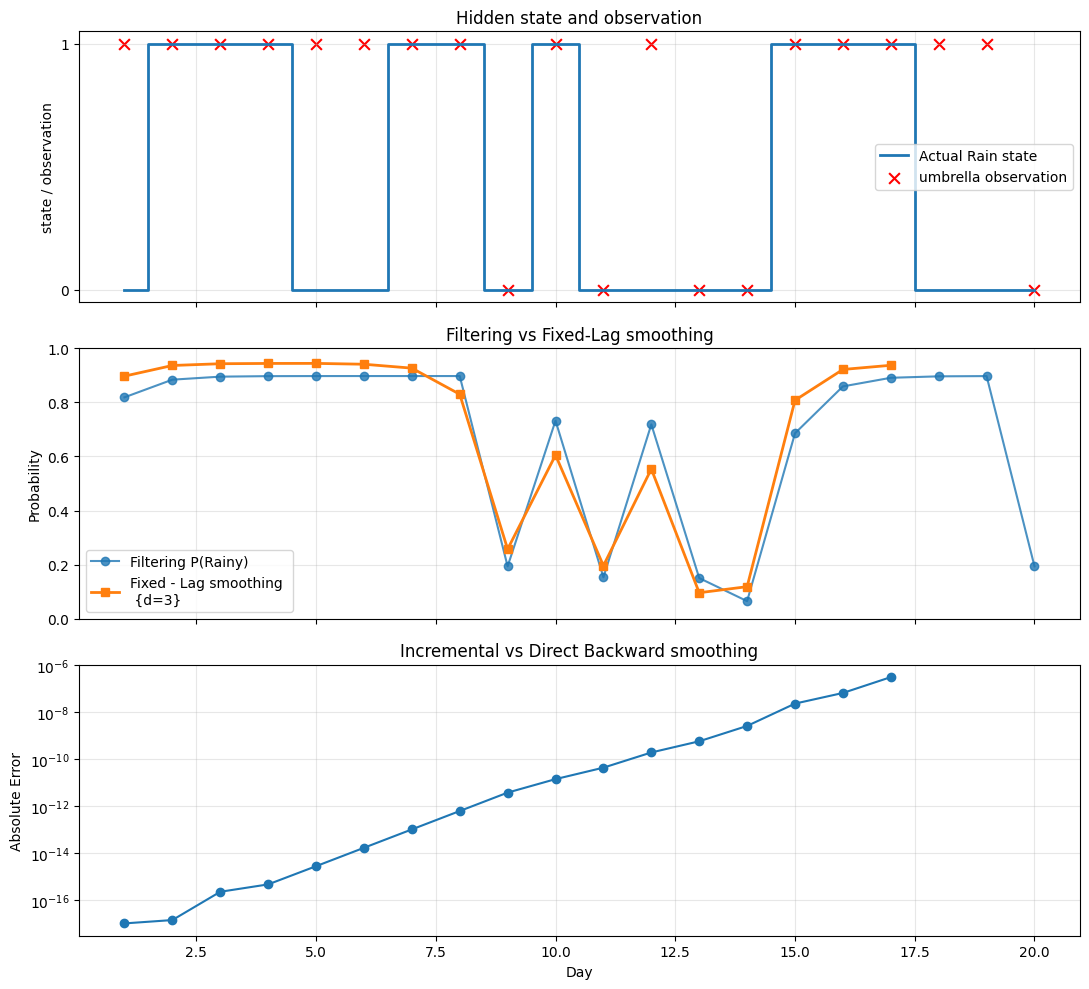

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

T = np.array([[0.7, 0.3],
              [0.3, 0.7]])

O = {
    1: np.diag([0.9, 0.2]),
    0: np.diag([0.1, 0.8])
}

N, d = 20, 3

rng = np.random.default_rng(12)

hidden = []
observation = []

state = rng.choice(2, p=[0.5, 0.5])

for i in range(N):
    state = rng.choice(2, p=T[state])
    umbrella = int(rng.random() < [0.9, 0.2][state])
    hidden.append(state)
    observation.append(umbrella)

print("observation:", observation)

def filter_step(F, e):
    F = O[e] @ T.T @ F
    return F / F.sum()

F = np.array([0.5, 0.5])
filtered = []

for obs in observation:
    F = filter_step(F, obs)
    filtered.append(F.copy())

filtered = np.array(filtered)

def backward(k, t):
    b = np.ones(2)
    for i in range(t-1, k-1, -1):
        b = T @ O[observation[i]] @ b
    return b

F = filtered[0].copy()
k = 1
t = k + d

B = np.eye(2)
for i in range(k, t):
    B = B @ T @ O[observation[i]]

smoothed = np.full((N, 2), np.nan)
errors = []

print("In current Day | Smoothed P(Rainy) | Not Rainy | Error")
print("-" * 60)

while True:
    b = B @ np.ones(2)
    smooth = F * b
    smooth = smooth / smooth.sum()

    smoothed[k-1] = smooth

    b_direct = backward(k, t)
    direct = F * b_direct
    direct = direct / direct.sum()

    error = np.max(np.abs(smooth - direct))
    errors.append(error)

    print(f"{t:11} | {k:12} | {smooth[0]:.4f}"
          f" | {smooth[1]:.4f} | {error:.2e}")

    if t == N:
        break

    B = np.linalg.solve(
        O[observation[k]],
        np.linalg.solve(T, B)
    ) @ T @ O[observation[t]]

    F = filter_step(F, observation[k])
    k += 1
    t += 1

print("\nMaximum verification error:", max(errors))

days = np.arange(1, N + 1)
valid = ~np.isnan(smoothed[:, 0])

fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

actual_rain = 1 - np.array(hidden)

ax[0].step(days, actual_rain, where="mid",
           label="Actual Rain state", linewidth=2)
ax[0].scatter(days, observation, marker='x',
              color="red", s=60, label="umbrella observation")
ax[0].set_ylabel("state / observation")
ax[0].set_title("Hidden state and observation")
ax[0].set_yticks([0, 1])
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(days, filtered[:, 0], "o-",
           label="Filtering P(Rainy)", alpha=0.8)
ax[1].plot(days[valid], smoothed[valid, 0],
           "s-",
           label=f"Fixed - Lag smoothing \n {{d={d}}}",
           linewidth=2)
ax[1].set_ylabel("Probability")
ax[1].set_title("Filtering vs Fixed-Lag smoothing")
ax[1].set_ylim(0, 1)
ax[1].legend()
ax[1].grid(True, alpha=0.3)

ax[2].semilogy(days[valid],
               np.maximum(errors, 1e-17), "o-")
ax[2].set_xlabel("Day")
ax[2].set_ylabel("Absolute Error")
ax[2].set_title("Incremental vs Direct Backward smoothing")
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("HMM_fixed_Lag_smoothing.png", dpi=300)
plt.show()